# Applying sLORETA on individual data

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm 
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Configuration file (`config`)
- `subjects`: list of subjects to process
- `samples`: list of samples to process


🎚️ **<font color=pink>Parameters</font>**
- Regularizer parameter (`lam`)
- Depth Weighting scale (`dw`)
- Window size (`win_size`): time window around EEG peak in [s]

In [2]:
# config
config   = mm.io.read_config("../configurations/spike.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])

# options
overwrite = True 

# parameters 
win_size = 0.1
lam      = 0.1
dw       = 1

# file naming
fstc = lambda sub, samp: mm_dir/sub/"inv"/f"{sub}_{samp}_sloreta-{lam}"

## ♾️ Loop

In [3]:
for sub in subjects:
    for samp in samples: 

        # check file existence 
        stc_fname = fstc(sub, samp)
        exists = mm.utils.files_exists(stc_fname)
        if exists and not overwrite:
            print(f"File to generate already exists for subject '{sub}' and sample '{samp}'")
            continue 

        try:
            data = mm.io.read_dataset(sub, "eeg_inv", "fwd", sample=samp)
            stc  = mm.sloreta(data["eeg_inv"], data["fwd"], lam, win_size)
        except Exception as e:
            print(f"\033[91mFailed to compute inverse solution for subject '{sub}', sample '{samp}' due to {e}\033[0m")
            continue

        # save
        stc.save(stc_fname, overwrite=True, verbose="warning")
        print(f"\033[92mSuccessfully computed sLORETA inverse solution for subject '{sub}', sample '{samp}'\033[0m")

Failed to compute inverse solution for subject 'sub-pat01', sample 'spike' due to File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/eeg/sub-pat01_clean_ave.fif"
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- eeg_inv
- fwd
Missing objects:
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Successfully computed sLORETA inverse solution for subject 'sub-pat02', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- eeg_inv
- fwd
Missing objects:
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Successfully computed sLORETA inverse solution for subject 'sub-pat03', sampl

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [2]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

## 🧠 Data

In [13]:
# configuration
config = mm.io.read_config("../configurations/spike.yml")
sub    = config["SUBS"][16]
sample = config["SAMP"][0]

# data
data = mm.io.read_dataset(sub, "gt", "eeg_inv", "fwd", "cst", "resec", "cst", sample=sample)

noise_cov = mne.make_ad_hoc_cov(data["eeg_inv"].info, std={"eeg":1})

# features
sfreq = data["eeg_inv"].info["sfreq"]


_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

DATA SUMMARY
Dataset: spike
Subject: sub-pat17
Retrieved objects:
- fwd
- resec
- cst
- eeg_inv
Missing objects:
- gt


#### 🌟 Visualize ground truth

In [14]:
if "gt" in data.keys():
    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)

else:
    plotter = mm.viz.plot_resection(data["fwd"]["src"], data["resec"])
    plotter.add_legend(face="circle")
    plotter.show()

Widget(value='<iframe src="http://localhost:40281/index.html?ui=P_0x71d2a2d7c1d0_8&reconnect=auto" class="pyvi…

In [15]:
if "gt" in data.keys():
    mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht]).show()

#### 🌟 Visualize EEG time series

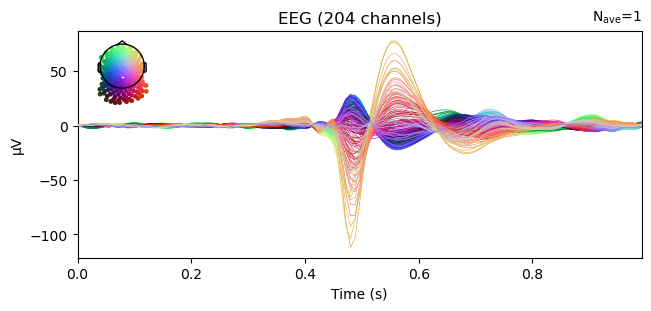

In [16]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

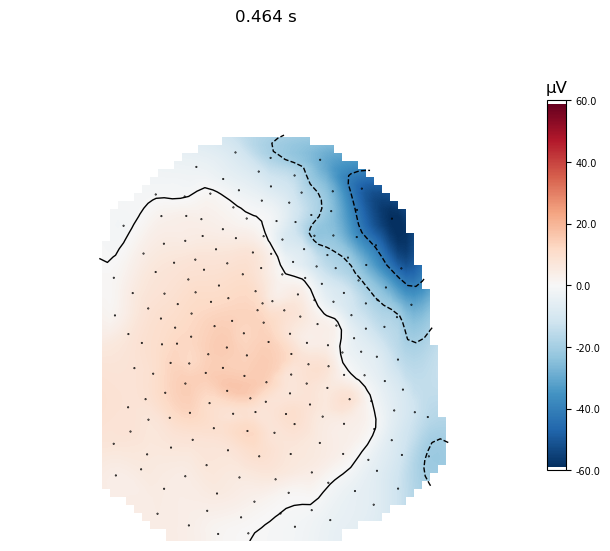

In [17]:
times = [t_half]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

## Solve the inverse problem with sLORETA

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct.
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 12


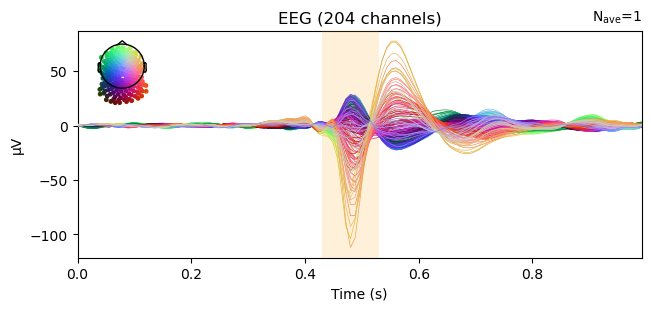

In [18]:
win_size = 0.1      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    b  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    b = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {b.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

🛠️ <font color=violet>**Select sLORETA parameters**</font>: Select the regularizer parameter $\lambda$

In [19]:
lam = 0.001

⚙️ <font color=green>**Solve inverse problem**</font>

In [20]:
data["eeg_inv"].set_eeg_reference(projection=True)

inverse = mne.minimum_norm.make_inverse_operator(
    data["eeg_inv"].info,
    data["fwd"],
    noise_cov,
    fixed=True,
    depth=None,
    verbose="warning",
)

stc = mne.minimum_norm.apply_inverse(
    data["eeg_inv"], 
    inverse, 
    lambda2=lam,
    method="sLORETA",
    verbose="warning",
)

stc = stc.crop(t_start, t_end)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


#### 🌟 Visualize reconstruction

In [21]:
viz = np.abs(stc.data) #/ (np.max(np.abs(stc.data), axis=0)+1e-15) 
mm.viz.plot_brain_time_series(data["fwd"]["src"], viz, t_start=t_start, sfreq=data["eeg_inv"].info["sfreq"], cmap="reds")

Widget(value='<iframe src="http://localhost:40281/index.html?ui=P_0x71d29ab2e4b0_9&reconnect=auto" class="pyvi…

In [22]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(stc.data[:,idx_half]), cmap="reds", show_max=True).show()

Widget(value='<iframe src="http://localhost:40281/index.html?ui=P_0x71d29874e0c0_11&reconnect=auto" class="pyv…

In [35]:
mm.viz.plot_spectrum(data["cst"]@stc.data[:,idx_half])

#### 💾 Save the sLORETA reconstruction

In [148]:
fname  = f"{sub}_{sample}_sloreta-{lam}"
folder = Path(config["MM_DIR"])/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving sLORETA reconstruction of {sample} from {sub}.")
stc.save(folder/fname, overwrite=True)

Saving sLORETA reconstruction of sample7 from sub-pat25.
Writing STC to disk...
[done]


#### 💾 Save the sLORETA reconstruction in brain vision format

In [ ]:
save = "mne"
#save = "bv"

fname  = f"{sub}_sloreta-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation for subject: {sub}")
if save == "mne":
    stc.save(folder/fname, overwrite=True)
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )

# Applying sLORETA on dataset

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Forward solution (`fwd`): lead field matrix for inversion
- EEG (`eeg_inv`): data to inverse

In [2]:
# config
config   = mm.io.read_config("../configurations/simf.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])
fname    = lambda sub, samp, lam: mm_dir/sub/"inv"/f"{sub}_{samp}_sloreta-{lam}"

# parameters
win_size = 0.1 
lam      = 0.001 
dw       = 1
scale    = 1

In [3]:
for sub in config["SUBS"]:
    for samp in config["SAMP"]:
        try: 
            data = mm.io.read_dataset(sub, "eeg_inv", "fwd", "cst", sample=samp)
            stc  = mm.sloreta(data["eeg_inv"], data["fwd"], lam, win_size)
        except Exception as e:
            print(f"\033[91mSkipped {sub}, {samp} due to {e}\033[0m")
            continue

        file = fname(sub, samp, lam)
        if not file.parent.exists():
            file.parent.mkdir()

        stc.save(fname(sub, samp, lam), overwrite=True, verbose="warning")
        print(f"\033[92m{sub}, {samp} successfully reconstructed\033[0m")

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
vepcon_sub-10, sample1 successfully reconstructed
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
vepcon_sub-10, sample2 successfully reconstructed
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
vepcon_sub-10, sample3 successfully reconstructed
EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not bee